In [ ]:

import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")


TensorFlow version: 2.21.0
Libraries imported successfully!


In [ ]:

# Load the Fashion-MNIST dataset
fashion_mnist = tf.keras.datasets.fashion_mnist

(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

# Examine dataset dimensions
print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


In [ ]:

class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

print("Number of classes:", len(class_names))

for index, name in enumerate(class_names):
    print(index, ":", name)


Number of classes: 10
0 : T-shirt/top
1 : Trouser
2 : Pullover
3 : Dress
4 : Coat
5 : Sandal
6 : Shirt
7 : Sneaker
8 : Bag
9 : Ankle boot


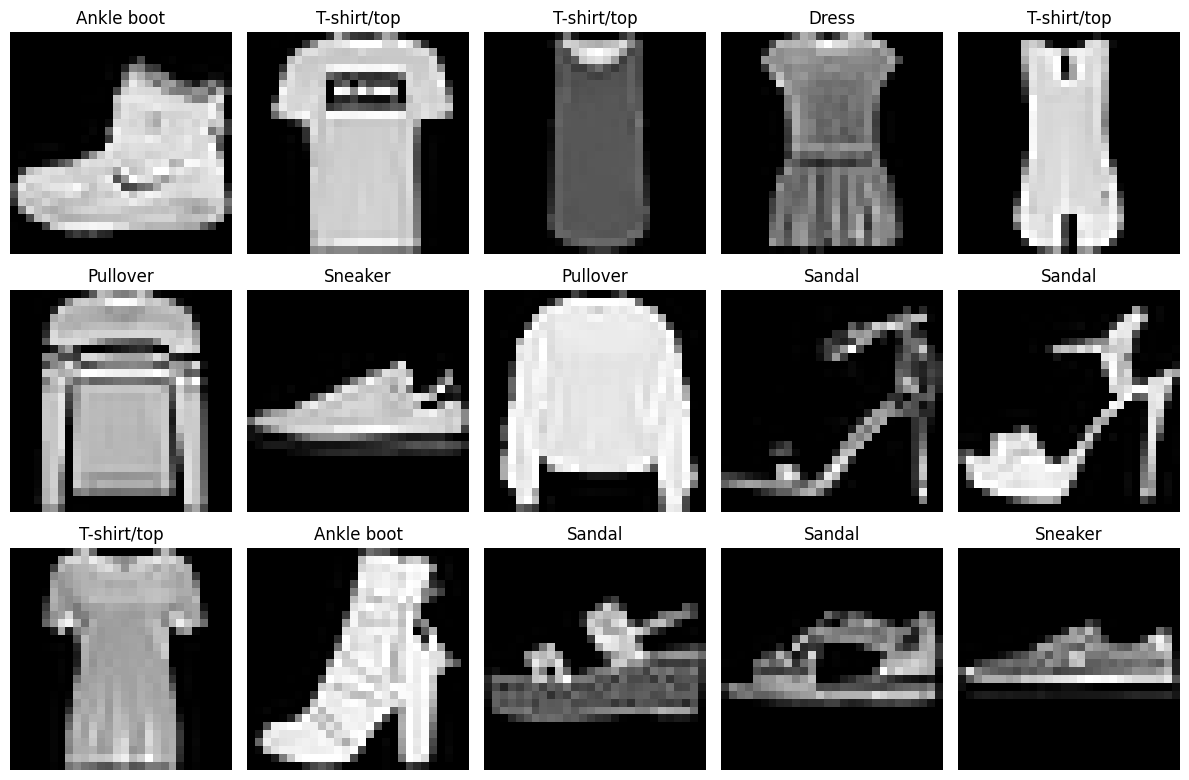

In [ ]:

plt.figure(figsize=(12, 8))

for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()


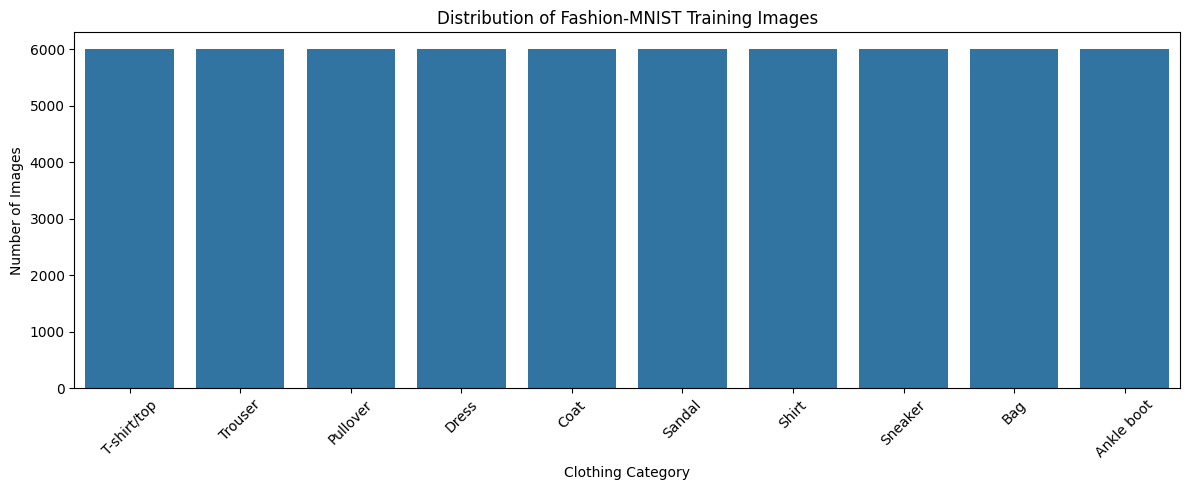

T-shirt/top: 6000 images
Trouser: 6000 images
Pullover: 6000 images
Dress: 6000 images
Coat: 6000 images
Sandal: 6000 images
Shirt: 6000 images
Sneaker: 6000 images
Bag: 6000 images
Ankle boot: 6000 images


In [ ]:

# Count images in each training class
class_counts = np.bincount(y_train, minlength=10)

plt.figure(figsize=(12, 5))

sns.barplot(
    x=class_names,
    y=class_counts
)

plt.title("Distribution of Fashion-MNIST Training Images")
plt.xlabel("Clothing Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

for name, count in zip(class_names, class_counts):
    print(f"{name}: {count} images")


In [ ]:
import os
from PIL import Image

np.random.seed(42)
tf.random.set_seed(42)

def save_split(X, y, split_dir, limit_per_class=None):
    counts = {}
    for img, label in zip(X, y):
        name = class_names[label].replace("/", "-")
        counts[name] = counts.get(name, 0)
        if limit_per_class and counts[name] >= limit_per_class:
            continue
        folder = os.path.join(split_dir, name)
        os.makedirs(folder, exist_ok=True)
        Image.fromarray(img).save(os.path.join(folder, f"{counts[name]}.png"))
        counts[name] += 1

# Limit per class keeps the GitHub repo small (zip must be submitted)
save_split(X_train, y_train, "../data/train", limit_per_class=500)
save_split(X_test, y_test, "../data/test", limit_per_class=100)
print("Images saved.")

Images saved.


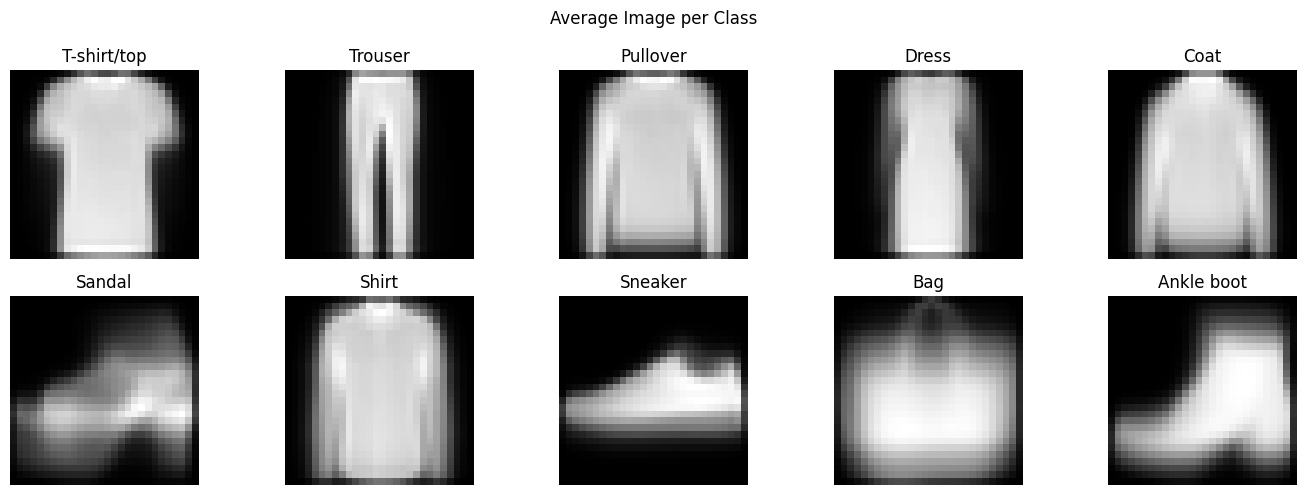

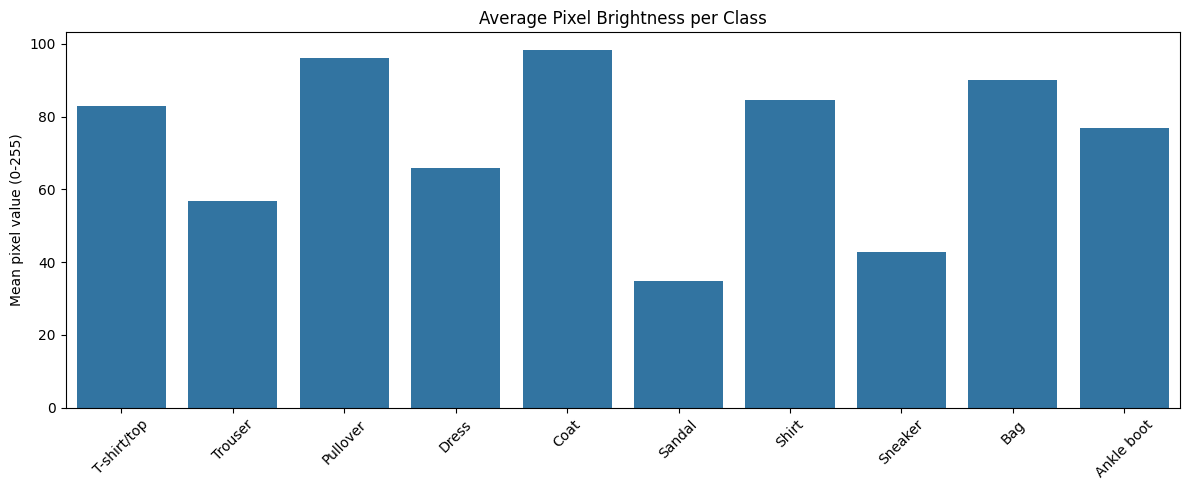

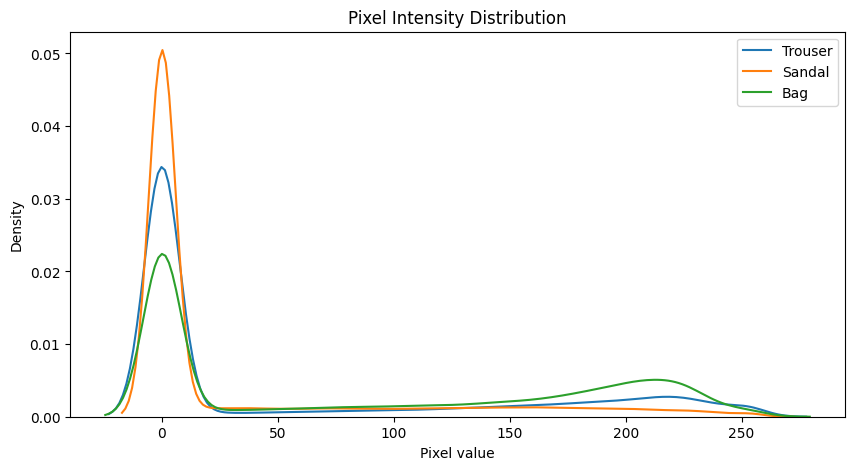

In [ ]:
# Visualization 2: Average image per class
plt.figure(figsize=(14, 5))
for i, name in enumerate(class_names):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[y_train == i].mean(axis=0), cmap="gray")
    plt.title(name)
    plt.axis("off")
plt.suptitle("Average Image per Class")
plt.tight_layout()
plt.show()

# Visualization 3: Mean pixel intensity (brightness) per class
mean_brightness = [X_train[y_train == i].mean() for i in range(10)]
plt.figure(figsize=(12, 5))
sns.barplot(x=class_names, y=mean_brightness)
plt.title("Average Pixel Brightness per Class")
plt.ylabel("Mean pixel value (0-255)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Visualization 4: Pixel intensity distribution for 3 classes
plt.figure(figsize=(10, 5))
for i in [1, 5, 8]:  # Trouser, Sandal, Bag
    sns.kdeplot(X_train[y_train == i].flatten()[:200000], label=class_names[i])
plt.title("Pixel Intensity Distribution")
plt.xlabel("Pixel value")
plt.legend()
plt.show()



```
# This is formatted as code
```

Coats (~98) and Pullovers (~96) are the brightest classes because they fill much of the 28x28 frame. Bags (~90) are also bright because they are large, solid objects. Sandals (~35) and Sneakers (~43) are the darkest because they are small, thin, or open objects that leave most of the image as black background. Brightness therefore works as a rough proxy for object size and can separate footwear from tops. It cannot separate similar tops (T-shirt 83, Shirt 84.5, Pullover 96, Coat 98), which sit close together. Confusion among those classes is expected.

All three classes have a large spike at 0, which is the black background. Sandals have the tallest spike and an almost flat tail, which means mostly empty image with few bright pixels. Bags have the lowest background peak and a clear second bump around 210 to 220, showing large, uniformly bright regions. Trousers fall in between, with a small bright bump near 220 to 250. The shape of the distribution therefore reflects how much of the frame the item fills and how solid it is, and that gives the CNN useful signal beyond the outline.

In [ ]:
# Normalize to 0-1 and add channel dimension
X_train_n = (X_train / 255.0).reshape(-1, 28, 28, 1).astype("float32")
X_test_n = (X_test / 255.0).reshape(-1, 28, 28, 1).astype("float32")

# Validation split
from sklearn.model_selection import train_test_split
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_n, y_train, test_size=0.1, stratify=y_train, random_state=42
)
print(X_tr.shape, X_val.shape, X_test_n.shape)

# Data augmentation (used in the optimized model)
augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.1),
])

(54000, 28, 28, 1) (6000, 28, 28, 1) (10000, 28, 28, 1)


In [ ]:
# Baseline: simple dense network
baseline = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax"),
])
baseline.compile(optimizer="adam",
                 loss="sparse_categorical_crossentropy",
                 metrics=["accuracy"])
hist_base = baseline.fit(X_tr, y_tr, validation_data=(X_val, y_val),
                         epochs=10, batch_size=64, verbose=1)

# Optimized: CNN with augmentation, BatchNorm, Dropout, L2, early stopping
from tensorflow.keras import layers, regularizers

cnn = tf.keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    augment,
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation="relu", kernel_regularizer=regularizers.l2(1e-4)),
    layers.Dropout(0.4),
    layers.Dense(10, activation="softmax"),
])
cnn.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"])

callbacks = [
    tf.keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(patience=2, factor=0.5),
]
hist_cnn = cnn.fit(X_tr, y_tr, validation_data=(X_val, y_val),
                   epochs=30, batch_size=64, callbacks=callbacks, verbose=1)

Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.8127 - loss: 0.5349 - val_accuracy: 0.8418 - val_loss: 0.4415
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8593 - loss: 0.3954 - val_accuracy: 0.8648 - val_loss: 0.3871
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8728 - loss: 0.3544 - val_accuracy: 0.8770 - val_loss: 0.3536
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.8805 - loss: 0.3276 - val_accuracy: 0.8802 - val_loss: 0.3372
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8875 - loss: 0.3078 - val_accuracy: 0.8852 - val_loss: 0.3281
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8933 - loss: 0.2911 - val_accuracy: 0.8857 - val_loss: 0.3198
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8983 - loss: 0.2784 - val_accuracy: 0.8855 - val_loss: 0.3186
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9031 - loss: 0.2659 - val_accuracy: 0.

In [ ]:
cnn.save("../models/fashion_cnn.keras")

I will use Use that in your write-up to wirite this

In [ ]:
def predict_image(model, image_path):
    img = Image.open(image_path).convert("L").resize((28, 28))
    arr = np.array(img).astype("float32") / 255.0
    # Fashion-MNIST items are light on a dark background.
    # If the photo has a white background, invert it.
    if arr.mean() > 0.5:
        arr = 1.0 - arr
    arr = arr.reshape(1, 28, 28, 1)
    probs = model.predict(arr, verbose=0)[0]
    idx = int(probs.argmax())
    return class_names[idx], float(probs[idx])

os.makedirs("../models", exist_ok=True)
cnn.save("../models/fashion_cnn.keras")


=== Baseline Dense ===
Accuracy : 0.8734
Precision: 0.876579898827748
Recall   : 0.8734
F1       : 0.8730828717438474
ROC-AUC  : 0.9897203611111112

=== Optimized CNN ===
Accuracy : 0.9169
Precision: 0.9170246459604579
Recall   : 0.9169
F1       : 0.9168610616803772
ROC-AUC  : 0.9951232277777778
              precision    recall  f1-score   support

 T-shirt/top       0.87      0.86      0.86      1000
     Trouser       0.99      0.99      0.99      1000
    Pullover       0.87      0.89      0.88      1000
       Dress       0.93      0.90      0.92      1000
        Coat       0.86      0.89      0.87      1000
      Sandal       0.99      0.97      0.98      1000
       Shirt       0.76      0.75      0.75      1000
     Sneaker       0.95      0.98      0.96      1000
         Bag       0.98      0.98      0.98      1000
  Ankle boot       0.98      0.96      0.97      1000

    accuracy                           0.92     10000
   macro avg       0.92      0.92      0.92     1000

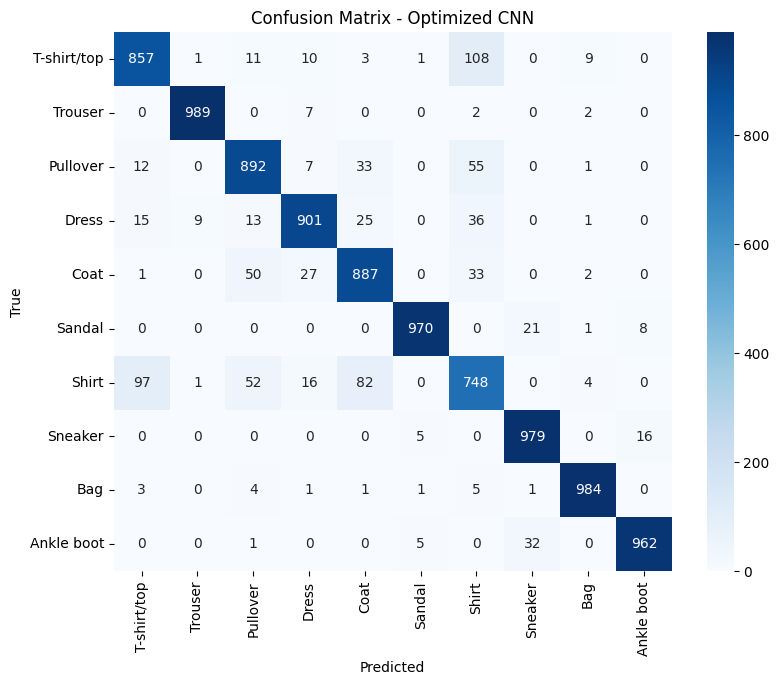

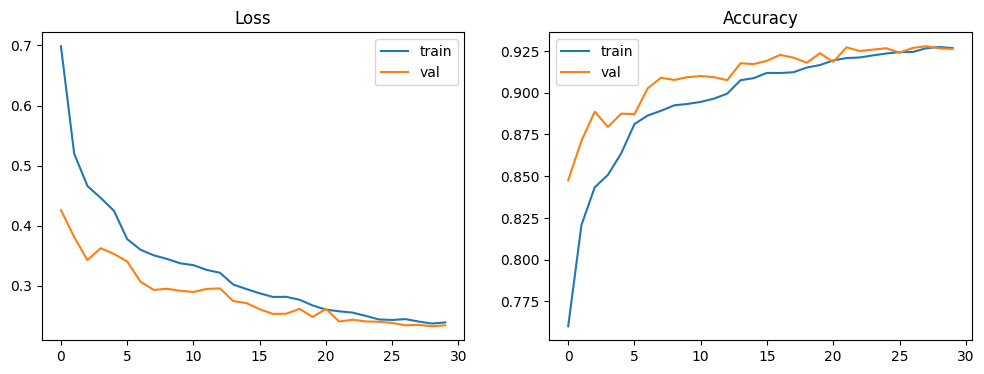

In [ ]:
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

def evaluate(model, name):
    probs = model.predict(X_test_n, verbose=0)
    preds = probs.argmax(axis=1)
    print(f"\n=== {name} ===")
    print("Accuracy :", accuracy_score(y_test, preds))
    print("Precision:", precision_score(y_test, preds, average="macro"))
    print("Recall   :", recall_score(y_test, preds, average="macro"))
    print("F1       :", f1_score(y_test, preds, average="macro"))
    print("ROC-AUC  :", roc_auc_score(y_test, probs, multi_class="ovr"))
    return preds

preds_base = evaluate(baseline, "Baseline Dense")
preds_cnn = evaluate(cnn, "Optimized CNN")

print(classification_report(y_test, preds_cnn, target_names=class_names))

# Confusion matrix
cm = confusion_matrix(y_test, preds_cnn)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("True")
plt.title("Confusion Matrix - Optimized CNN")
plt.show()

# Training curves
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist_cnn.history["loss"], label="train")
ax[0].plot(hist_cnn.history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(hist_cnn.history["accuracy"], label="train")
ax[1].plot(hist_cnn.history["val_accuracy"], label="val")
ax[1].set_title("Accuracy"); ax[1].legend()
plt.show()

The CNN reached 91.7% test accuracy versus 87.3% for the dense baseline. Nearly all remaining errors come from visually similar upper-body garments, especially Shirt, whose recall (0.75) is the lowest. Footwear and bags are classified almost perfectly. The training curves show validation loss tracking training loss closely, so the regularization (dropout, L2, augmentation) is working. Validation accuracy sits slightly above training accuracy early on because dropout and augmentation are active only during training.

In [ ]:
import json
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

metrics = {
    "accuracy": float(accuracy_score(y_test, preds_cnn)),
    "precision": float(precision_score(y_test, preds_cnn, average="macro")),
    "recall": float(recall_score(y_test, preds_cnn, average="macro")),
    "f1": float(f1_score(y_test, preds_cnn, average="macro")),
    "model_version": 1,
}
with open("../models/metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

cnn.save("../models/fashion_cnn.keras")

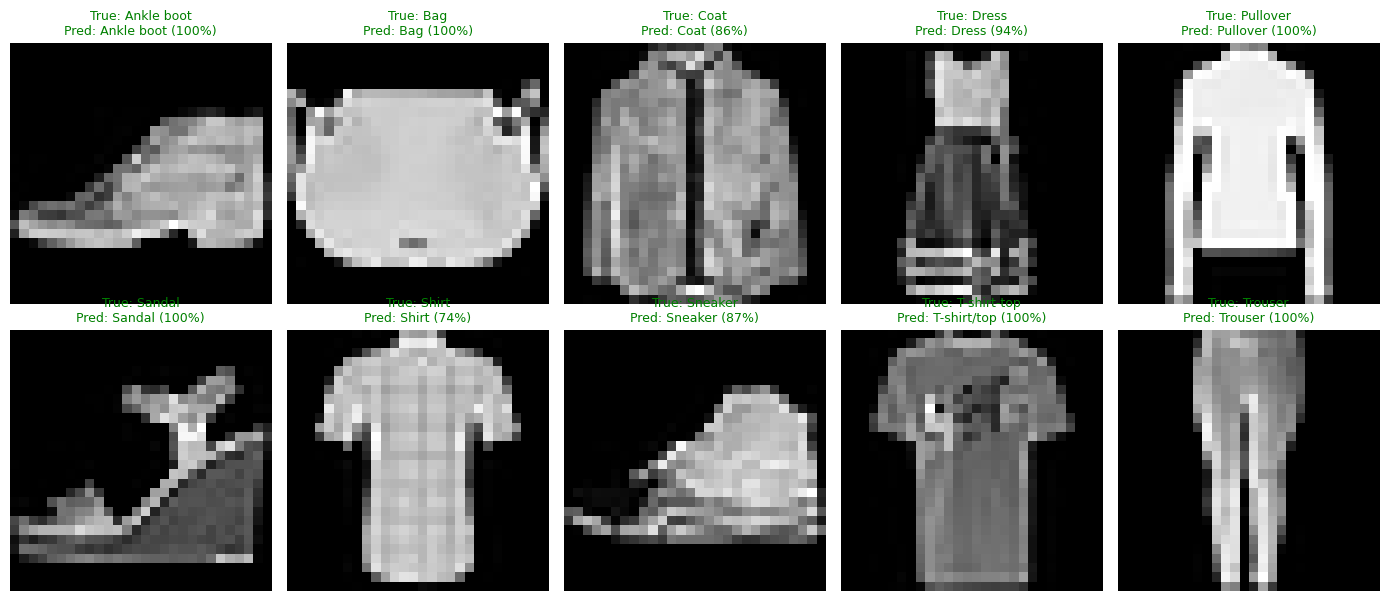

Correct: 10/10
Original  : ('Sneaker', 0.9996368885040283)
White bg  : ('Sneaker', 0.9996368885040283)


In [ ]:
import glob, random

random.seed(42)
test_root = "../data/test"
folders = sorted(os.listdir(test_root))

# Test 1: one random saved test image per class
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
correct = 0
for ax, folder in zip(axes.ravel(), folders):
    path = random.choice(glob.glob(os.path.join(test_root, folder, "*.png")))
    label, conf = predict_image(cnn, path)
    ok = label.replace("/", "-") == folder
    correct += ok
    ax.imshow(Image.open(path), cmap="gray")
    ax.set_title(f"True: {folder}\nPred: {label} ({conf:.0%})",
                 color="green" if ok else "red", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()
print(f"Correct: {correct}/{len(folders)}")

# Test 2: white-background version of the same image
# (simulates a real photo; checks that the inversion step works)
sample = random.choice(glob.glob(os.path.join(test_root, "Sneaker", "*.png")))
inverted = Image.fromarray(255 - np.array(Image.open(sample)))
inverted.save("white_bg_test.png")
print("Original  :", predict_image(cnn, sample))
print("White bg  :", predict_image(cnn, "white_bg_test.png"))
os.remove("white_bg_test.png")

In [ ]:
import os

cache_dir = os.path.expanduser('~/.keras/datasets/fashion-mnist')
print(os.listdir(cache_dir))


['t10k-labels-idx1-ubyte.gz', 'train-labels-idx1-ubyte.gz', 't10k-images-idx3-ubyte.gz', 'train-images-idx3-ubyte.gz']


In [ ]:
!zip -r project_files.zip /data /models
from google.colab import files
files.download("project_files.zip")

Streaming output truncated to the last 5000 lines.
  adding: data/train/Bag/499.png (stored 0%)
  adding: data/train/Bag/434.png (stored 0%)
  adding: data/train/Bag/114.png (stored 0%)
  adding: data/train/Bag/365.png (stored 0%)
  adding: data/train/Bag/485.png (stored 0%)
  adding: data/train/Bag/179.png (stored 0%)
  adding: data/train/Bag/494.png (stored 0%)
  adding: data/train/Bag/152.png (stored 0%)
  adding: data/train/Bag/217.png (stored 0%)
  adding: data/train/Bag/207.png (stored 0%)
  adding: data/train/Bag/345.png (stored 0%)
  adding: data/train/Bag/275.png (stored 0%)
  adding: data/train/Bag/154.png (stored 0%)
  adding: data/train/Bag/306.png (stored 0%)
  adding: data/train/Bag/146.png (stored 0%)
  adding: data/train/Bag/475.png (stored 0%)
  adding: data/train/Bag/292.png (stored 0%)
  adding: data/train/Bag/189.png (stored 0%)
  adding: data/train/Bag/197.png (stored 0%)
  adding: data/train/Bag/441.png (stored 0%)
  adding: data/train/Bag/305.png (stored 0%)
  ad

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>